In [1]:

import pandas as pd
import numpy as np

# Reproducible synthetic logistics dataset
rng = np.random.default_rng(42)
n = 1500

vehicle_types = rng.choice(
    ["Bike", "Van", "Truck"], n, p=[0.40, 0.40, 0.20]
)
traffic_levels = rng.choice(
    ["Low", "Medium", "High"], n, p=[0.30, 0.45, 0.25]
)
weather_conditions = rng.choice(
    ["Normal", "Rain", "Storm"], n, p=[0.75, 0.18, 0.07]
)
zones = rng.choice(
    ["Urban", "Suburban", "Semi-urban", "Rural"], n
)

distance = rng.uniform(2, 60, n)
packages = rng.integers(1, 31, n)
weight = packages * rng.uniform(1.0, 8.0, n)
shipment_volume = packages * rng.uniform(0.2, 1.5, n)
hour = rng.integers(6, 23, n)
day_of_week = rng.integers(0, 7, n)

# Effects used to simulate realistic delivery-time patterns
vehicle_effect = pd.Series(vehicle_types).map({
    "Bike": 0, "Van": 8, "Truck": 18
}).to_numpy()

traffic_effect = pd.Series(traffic_levels).map({
    "Low": 0, "Medium": 15, "High": 35
}).to_numpy()

weather_effect = pd.Series(weather_conditions).map({
    "Normal": 0, "Rain": 10, "Storm": 25
}).to_numpy()

zone_effect = pd.Series(zones).map({
    "Urban": 12, "Suburban": 5,
    "Semi-urban": 8, "Rural": 15
}).to_numpy()

rush_hour_effect = np.where(
    ((hour >= 7) & (hour <= 10)) |
    ((hour >= 16) & (hour <= 19)),
    12, 0
)

# Delivery time is the target variable (minutes)
noise = rng.normal(0, 8, n)

delivery_time = (
    12
    + distance * 1.8
    + packages * 0.7
    + weight * 0.08
    + vehicle_effect
    + traffic_effect
    + weather_effect
    + zone_effect
    + rush_hour_effect
    + noise
)

delivery_time = np.maximum(delivery_time, 10)

# Assemble dataset
logistics_df = pd.DataFrame({
    "Distance_KM": distance.round(2),
    "Package_Count": packages,
    "Load_Weight_KG": weight.round(2),
    "Shipment_Volume": shipment_volume.round(2),
    "Vehicle_Type": vehicle_types,
    "Traffic_Level": traffic_levels,
    "Weather_Condition": weather_conditions,
    "Destination_Zone": zones,
    "Dispatch_Hour": hour,
    "Day_of_Week": day_of_week,
    "Rush_Hour": ((hour >= 7) & (hour <= 10)) |
                 ((hour >= 16) & (hour <= 19)),
    "Delivery_Time_Minutes": delivery_time.round(2)
})

# Initial data quality checks
print("Dataset shape:", logistics_df.shape)
print("\nMissing values:", logistics_df.isnull().sum().sum())
print("Duplicate rows:", logistics_df.duplicated().sum())

display(logistics_df.head())
display(logistics_df.describe().round(2))


Dataset shape: (1500, 12)

Missing values: 0
Duplicate rows: 0


,Distance_KM,Package_Count,Load_Weight_KG,Shipment_Volume,Vehicle_Type,Traffic_Level,Weather_Condition,Destination_Zone,Dispatch_Hour,Day_of_Week,Rush_Hour,Delivery_Time_Minutes
0,29.80,6,27.06,8.01,Van,Medium,Rain,Suburban,9,4,True,124.23
1,5.60,1,6.13,0.52,Van,High,Normal,Urban,12,3,False,68.59
2,16.97,14,32.45,11.70,Truck,Medium,Normal,Semi-urban,18,0,True,104.70
3,48.63,9,36.96,2.15,Van,Medium,Normal,Suburban,6,5,False,131.69
4,45.60,1,4.73,0.21,Bike,High,Normal,Rural,21,2,False,137.27


,Distance_KM,Package_Count,Load_Weight_KG,Shipment_Volume,Dispatch_Hour,Day_of_Week,Delivery_Time_Minutes
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00
mean,30.71,15.57,70.68,13.22,14.14,3.06,125.07
std,16.73,8.64,53.28,10.12,4.89,1.99,37.75
min,2.02,1.00,1.08,0.21,6.00,0.00,27.54
25%,16.23,8.00,28.59,4.96,10.00,1.00,96.57
50%,30.88,16.00,55.99,10.34,14.00,3.00,124.66
75%,45.29,23.00,105.38,19.90,18.00,5.00,152.02
max,59.97,30.00,234.46,44.58,22.00,6.00,236.44


In [2]:

# STEP 2: Data Preparation and Train-Test Split

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# 1. Define target and input features
target_column = "Delivery_Time_Minutes"

X = logistics_df.drop(columns=[target_column])
y = logistics_df[target_column]

# 2. Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Include the Boolean Rush_Hour column as a numeric feature
if "Rush_Hour" in X.columns:
    numeric_features.append("Rush_Hour")

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# 3. Create preprocessing pipelines
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# 4. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 5. Verify there are no missing values in the target
print("\nMissing training targets:", y_train.isnull().sum())
print("Missing testing targets:", y_test.isnull().sum())


Numerical features: ['Distance_KM', 'Package_Count', 'Load_Weight_KG', 'Shipment_Volume', 'Dispatch_Hour', 'Day_of_Week', 'Rush_Hour']
Categorical features: ['Vehicle_Type', 'Traffic_Level', 'Weather_Condition', 'Destination_Zone']

Training feature shape: (1200, 11)
Testing feature shape: (300, 11)
Training target shape: (1200,)
Testing target shape: (300,)

Training samples: 1200
Testing samples: 300

Missing training targets: 0
Missing testing targets: 0


In [3]:

# STEP 3: Train and Compare Predictive Models

import pandas as pd
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define models
models = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )
}

# 2. Train each model and evaluate on the test set
trained_models = {}
results = []

for model_name, model in models.items():

    # Preprocessing is fitted only on the training data
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "MAE (minutes)": round(mae, 2),
        "RMSE (minutes)": round(rmse, 2),
        "R²": round(r2, 4)
    })

# 3. Display comparison
results_df = pd.DataFrame(results).sort_values(
    by="RMSE (minutes)"
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results_df)

# 4. Identify the best model by test RMSE
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Best model by test RMSE:", best_model_name)


MODEL PERFORMANCE COMPARISON


,Model,MAE (minutes),RMSE (minutes),R²
0,Linear Regression,5.80,7.50,0.9548
1,Random Forest,8.89,11.29,0.8976
2,Baseline (Mean),28.87,35.53,-0.0148


Best model by test RMSE: Linear Regression


In [4]:

# STEP 4: Cross-Validation and Hyperparameter Tuning

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

# 1. Define 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Compare linear models using training data only
cv_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=10000)
}

cv_results = []

for name, model in cv_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV RMSE": round(-scores.mean(), 3),
        "CV RMSE Std": round(scores.std(), 3)
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV RMSE"
).reset_index(drop=True)

print("5-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df)

# 3. Tune Ridge regularization strength
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("\nBEST RIDGE PARAMETERS:", ridge_search.best_params_)
print("BEST RIDGE CV RMSE:", round(-ridge_search.best_score_, 3), "minutes")

# 4. Save the best tuned Ridge model for later comparison
tuned_ridge_model = ridge_search.best_estimator_


5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean CV RMSE,CV RMSE Std
0,Ridge,7.986,0.075
1,Linear Regression,7.987,0.079
2,Lasso,10.331,0.835



BEST RIDGE PARAMETERS: {'model__alpha': 1.0}
BEST RIDGE CV RMSE: 7.986 minutes


In [5]:

# STEP 5A: Compare Tuned Ridge Against Linear Regression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Use the existing Linear Regression model from Step 3
linear_model = trained_models["Linear Regression"]

# Tuned Ridge model was created in Step 4
models_to_compare = {
    "Linear Regression": linear_model,
    "Tuned Ridge": tuned_ridge_model
}

test_results = []
test_predictions = {}

for name, model in models_to_compare.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions

    test_results.append({
        "Model": name,
        "MAE (minutes)": round(mean_absolute_error(y_test, predictions), 3),
        "RMSE (minutes)": round(
            np.sqrt(mean_squared_error(y_test, predictions)), 3
        ),
        "R²": round(r2_score(y_test, predictions), 4)
    })

test_results_df = pd.DataFrame(test_results).sort_values(
    by="RMSE (minutes)"
).reset_index(drop=True)

print("FINAL TEST-SET MODEL COMPARISON")
display(test_results_df)

# Select the model with the lower test RMSE
if test_results_df.loc[0, "Model"] == "Tuned Ridge":
    final_model = tuned_ridge_model
    final_model_name = "Tuned Ridge"
else:
    final_model = linear_model
    final_model_name = "Linear Regression"

print("Selected model:", final_model_name)


FINAL TEST-SET MODEL COMPARISON


,Model,MAE (minutes),RMSE (minutes),R²
0,Tuned Ridge,5.796,7.493,0.9549
1,Linear Regression,5.798,7.496,0.9548


Selected model: Tuned Ridge


In [6]:

# STEP 5B: Dispatch-Hour Optimization Simulation

# Select 20 representative deliveries from the test set
sample_deliveries = X_test.head(20).copy().reset_index(drop=True)

optimization_results = []

for i, delivery in sample_deliveries.iterrows():

    # Predict delivery time at its current dispatch hour
    current_input = delivery.to_frame().T
    current_prediction = final_model.predict(current_input)[0]
    current_hour = int(delivery["Dispatch_Hour"])

    # Test each possible dispatch hour
    candidate_inputs = pd.concat(
        [delivery.to_frame().T] * 17,
        ignore_index=True
    )

    candidate_inputs["Dispatch_Hour"] = list(range(6, 23))
    candidate_inputs["Rush_Hour"] = (
        candidate_inputs["Dispatch_Hour"].between(7, 10)
        | candidate_inputs["Dispatch_Hour"].between(16, 19)
    )

    candidate_predictions = final_model.predict(candidate_inputs)

    best_index = int(np.argmin(candidate_predictions))
    recommended_hour = 6 + best_index
    best_prediction = float(candidate_predictions[best_index])

    optimization_results.append({
        "Delivery_ID": i + 1,
        "Original_Hour": current_hour,
        "Original_Predicted_Minutes": round(current_prediction, 2),
        "Recommended_Hour": recommended_hour,
        "Optimized_Predicted_Minutes": round(best_prediction, 2),
        "Estimated_Time_Saved_Minutes": round(
            current_prediction - best_prediction, 2
        )
    })

optimization_df = pd.DataFrame(optimization_results)

print("DISPATCH-HOUR OPTIMIZATION RESULTS")
display(optimization_df)

print("\nSUMMARY")
print(
    "Average estimated time saved:",
    round(optimization_df["Estimated_Time_Saved_Minutes"].mean(), 2),
    "minutes per delivery"
)
print(
    "Deliveries with a predicted improvement:",
    int((optimization_df["Estimated_Time_Saved_Minutes"] > 0).sum()),
    "out of",
    len(optimization_df)
)


DISPATCH-HOUR OPTIMIZATION RESULTS


,Delivery_ID,Original_Hour,Original_Predicted_Minutes,Recommended_Hour,Optimized_Predicted_Minutes,Estimated_Time_Saved_Minutes
0,1,17,113.46,6,101.18,12.28
1,2,14,107.26,6,107.01,0.25
2,3,20,87.24,6,86.80,0.44
3,4,22,86.11,6,85.61,0.50
4,5,22,51.77,6,51.27,0.50
5,6,10,101.01,6,88.95,12.06
6,7,10,84.43,6,72.36,12.06
7,8,13,108.52,6,108.30,0.22
8,9,17,98.67,6,86.38,12.28
9,10,16,141.75,6,129.50,12.25



SUMMARY
Average estimated time saved: 4.45 minutes per delivery
Deliveries with a predicted improvement: 20 out of 20


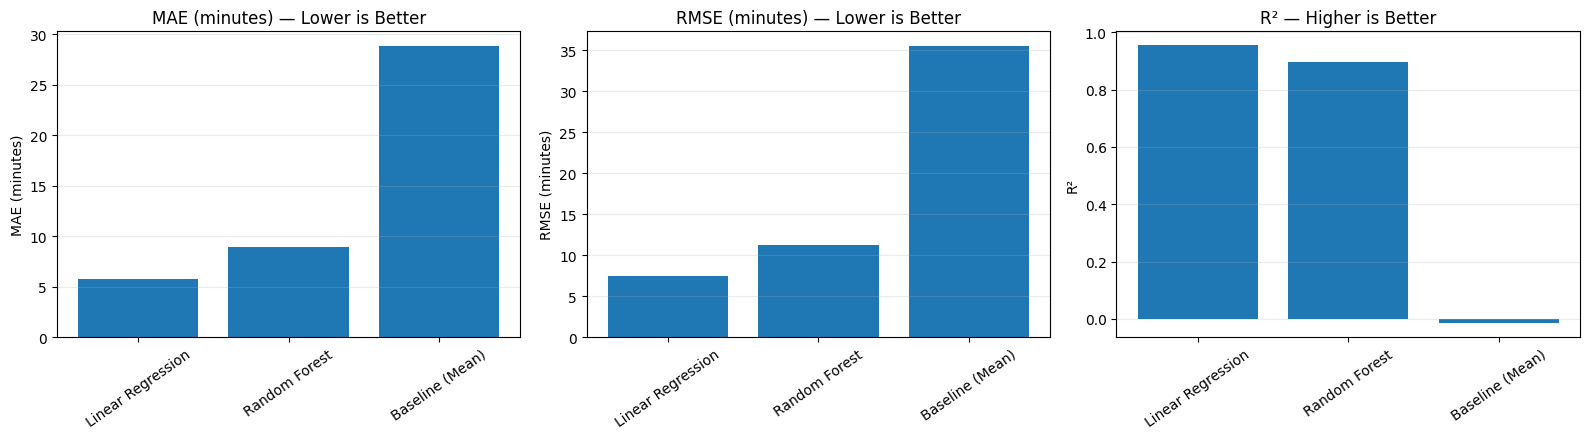

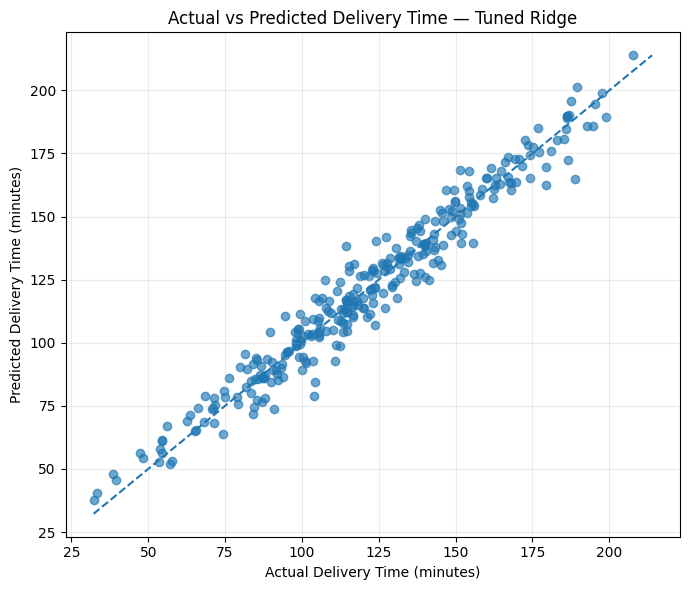

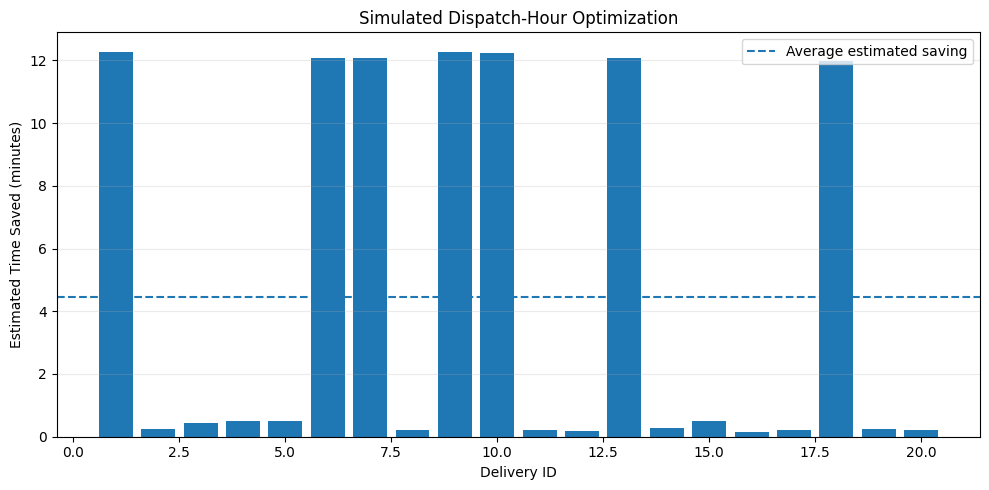

Saved 3 charts and 4 CSV result tables.
Average simulated time saved: 4.45 minutes per delivery


In [7]:

# STEP 6: Visualizations for the Report

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Chart 1: Compare model performance
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = [
    ("MAE (minutes)", "MAE (minutes) — Lower is Better"),
    ("RMSE (minutes)", "RMSE (minutes) — Lower is Better"),
    ("R²", "R² — Higher is Better")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 2: Actual vs predicted delivery times for Tuned Ridge
ridge_predictions = tuned_ridge_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, ridge_predictions, alpha=0.65)
min_value = min(y_test.min(), ridge_predictions.min())
max_value = max(y_test.max(), ridge_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time — Tuned Ridge")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 3: Estimated time savings from dispatch-hour optimization
plt.figure(figsize=(10, 5))
plt.bar(
    optimization_df["Delivery_ID"],
    optimization_df["Estimated_Time_Saved_Minutes"]
)
plt.axhline(
    optimization_df["Estimated_Time_Saved_Minutes"].mean(),
    linestyle="--",
    label="Average estimated saving"
)
plt.xlabel("Delivery ID")
plt.ylabel("Estimated Time Saved (minutes)")
plt.title("Simulated Dispatch-Hour Optimization")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("dispatch_optimization_savings.png", dpi=200, bbox_inches="tight")
plt.show()

# Save tables for the report and repository
results_df.to_csv("initial_model_comparison.csv", index=False)
cv_results_df.to_csv("cross_validation_results.csv", index=False)
test_results_df.to_csv("final_test_model_comparison.csv", index=False)
optimization_df.to_csv("dispatch_optimization_results.csv", index=False)

print("Saved 3 charts and 4 CSV result tables.")
print("Average simulated time saved:",
      round(optimization_df["Estimated_Time_Saved_Minutes"].mean(), 2),
      "minutes per delivery")


In [8]:
from google.colab import files
import os

# CSV files generated by your project
csv_files = [
    "initial_model_comparison.csv",
    "cross_validation_results.csv",
    "final_test_model_comparison.csv",
    "dispatch_optimization_results.csv"
]

# Check whether the files exist and download them
for filename in csv_files:
    if os.path.exists(filename):
        files.download(filename)
        print(f"Downloading: {filename}")
    else:
        print(f"File not found: {filename}")
        print("Check the file location in your Colab notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: initial_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloading: final_test_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: dispatch_optimization_results.csv


In [9]:
from google.colab import files
import os

image_extensions = (".png", ".jpg", ".jpeg")
image_files = []

for root, dirs, filenames in os.walk("/content"):
    for filename in filenames:
        if filename.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, filename))

if image_files:
    for image_path in image_files:
        print("Downloading:", os.path.basename(image_path))
        files.download(image_path)
else:
    print("No saved images found. Save your charts as PNG files first.")

Downloading: actual_vs_predicted.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: dispatch_optimization_savings.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: model_performance_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>